## The code herein was written with help from Claude on a function by function basis, reviewed by me.

# TJ Smith

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

In [11]:
# Logging customers into a list of dictionaries that show us what stage of the process we are in, what price we are testing, how many customers were tested at that price, and the total revenue at that price.
seed = 1234
pmin = 0
pmax = 70
testrange = np.random.default_rng(seed)
trueoptimal = 11.925

customers = []
pricescache = {}

def experiment(price, n, stage):
    """This function simulates an experiment at a given price, with a given number of customers, and then returns the revenue generated from that experiment. It also logs the results into a list of dictionaries for later analysis."""
    price = round(float(np.clip(price, pmin, pmax)),2)
    revenue = price * sales(price, mean_customers = n, rng = testrange)
    customers.append({"stage": stage, "price": price, "customers": len(revenue), "revenue": float(revenue.sum())})
    return revenue

def sample(price, n, stage):
    """This function gets n additional customers at a given price and appends them to our price cache."""
    price = round(float(price), 2)
    new = experiment(price, n, stage)
    pricescache[price] = np.concatenate([pricescache.get(price, np.empty(0)), new])
    return pricescache[price]

def summarize(prices, z):
    """This function gives us the mean rpc, standard error, and confidence interval for each price in the list of prices."""
    rows = []
    for p in prices:
        x = pricescache[round(float(p), 2)]
        m = x.mean() 
        se = x.std(ddof=1) / np.sqrt(len(x))
        rows.append({"price": round(float(p), 2), "n": len(x), "mean_revpc": m, "se": se, "low": m - z * se, "high": m + z * se})
    return pd.DataFrame(rows)

def eliminate(prices, z):
    """This function performs a two-sample z-test against the leading price, and eliminates prices where the confidence interval of the difference in mean rpc does not include zero."""
    tab = summarize(prices, z)
    lead = tab.loc[tab["mean_revpc"].idxmax()]
    delta = lead["mean_revpc"] - tab["mean_revpc"]
    se_delta = np.sqrt(lead["se"] ** 2 + tab["se"] ** 2)
    tab["delta_vs_leader"] = delta
    tab["ci_low_vs_leader"] = delta - z * se_delta
    tab["keep"] = (tab["price"] == lead["price"]) | (tab["ci_low_vs_leader"] <= 0)
    return tab

def customers_so_far():
    """This function returns the total number of customers that have been tested so far."""
    return sum(row["customers"] for row in customers)

def group_into_basins(prices, gap):
    """This function puts sorted prices into groups whenever consecutive prices are spearated by more than gap. It returns a list of lists of prices."""
    prices = sorted(prices)
    basins = [[prices[0]]]
    for p in prices[1:]:
        if p - basins[-1][-1] > gap + 1e-9:
            basins.append([p])
        else:
            basins[-1].append(p)
    return basins

In [12]:
step = 2.0 # This is our step size for our grid.
gaps = 2 * step #This is the gap size for the basin groupings.
N0 = 200 # This is the number of customers being tested at each price in the grid.
grid = np.arange(1.0, pmax, step) #This is our grid of prices to test given our step size and max price.
for p in grid:
    sample(p, N0, "1-grid")
grid_table = summarize(grid, z=2.0)
grid_table

,price,n,mean_revpc,se,low,high
0,1.0,225,1.000000,0.000000,1.000000,1.000000
1,3.0,150,3.000000,0.000000,3.000000,3.000000
2,5.0,210,5.000000,0.000000,5.000000,5.000000
3,7.0,180,7.000000,0.000000,7.000000,7.000000
4,9.0,198,9.000000,0.000000,9.000000,9.000000
5,11.0,216,10.898148,0.071852,10.754443,11.041853
6,13.0,190,11.289474,0.319647,10.650179,11.928768
7,15.0,185,8.108108,0.551087,7.005934,9.210282
8,17.0,191,8.099476,0.615970,6.867537,9.331416
9,19.0,181,9.552486,0.708077,8.136331,10.968641


In [13]:
zeliminate = 2.0 #This is the z-score for our two-sample z-test that we will use to elminate prices that are not statistically significantly different from the leading price.
active = list(grid_table["price"])
batch = N0
elim_log = []
for rnd in range(1, 7):
    tab = eliminate(active, zeliminate)
    elim_log.append({"round": rnd, "prices_tested": len(active),
                     "prices_kept": int(tab["keep"].sum()),
                     "customers_at_each": batch, "cumulative_customers": customers_so_far()})
    active = list(tab.loc[tab["keep"], "price"])
    if len(group_into_basins(active, gaps)) == 1:
        break
    batch *= 2
    for p in active:
        sample(p, batch, "2-elimination")
survivors = summarize(active, zeliminate)
elim_log = pd.DataFrame(elim_log)
display(elim_log)
display(survivors)


,round,prices_tested,prices_kept,customers_at_each,cumulative_customers
0,1,35,9,200,7009
1,2,9,6,400,10585
2,3,6,4,800,15338
3,4,4,2,1600,21686


,price,n,mean_revpc,se,low,high
0,27.0,2929,11.467395,0.246643,10.974109,11.960681
1,29.0,3003,11.878122,0.260282,11.357558,12.398686


In [14]:
basins = group_into_basins(active, gaps)

def estimate_gradient(price, *, step=1.0, mean_customers=300, bounds=(pmin, pmax), stage="3-gradient-ascent"):
    """This function estimates the gradient of the rpc with respect to price. It does this by running two experiments, one at price - step and one at price + step, and then calculating the difference in mean rpc between the two experiments. It also calculates the standard error of the difference in mean rpc, and returns a dictionary with the estimated gradient, standard error, and confidence interval."""
    if step <= 0:
        raise ValueError("step must be positive")
    lo_b, hi_b = bounds
    price = round(float(np.clip(price, lo_b, hi_b)), 2)
    price_low = max(pmin, price - step)
    price_high = min(pmax, price + step)
    low = experiment(price_low, mean_customers, stage)
    high = experiment(price_high, mean_customers, stage)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")
    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))
    gap = price_high - price_low
    return {"price": price, "gradient": difference / gap, "gradient_se": se / gap,
            "ci_low": (difference - 1.645 * se) / gap, "ci_high": (difference + 1.645 * se) / gap,
            "customers": len(low) + len(high)}

def gradient_ascent(start_price, bounds, iterations=30, step=1.0,learning_rate=2.0, mean_customers=300):
    """This function performs gradient ascent to find a price maximizing rpc"""
    lo_b, hi_b = bounds
    price = float(np.clip(start_price, lo_b, hi_b))
    records = []
    for iteration in range(iterations):
        est = estimate_gradient(price, step=step, mean_customers=mean_customers, bounds=bounds)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * est["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, lo_b, hi_b))
        records.append({"iteration": iteration + 1, **est,
                        "learning_rate": rate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)

candidates, ascent_paths = [], {}
for b in basins:
    sub = survivors[survivors["price"].isin(b)]
    start = float(sub.loc[sub["mean_revpc"].idxmax(), "price"])
    bounds = (max(pmin, min(b) - gaps), min(pmax, max(b) + gaps))
    path = gradient_ascent(start, bounds)
    ascent_paths[start] = path
    refined = path["next_price"].iloc[len(path) // 2:].mean()
    candidates.append(round(float(refined), 2))
candidates = [round(float(np.mean(g)), 2) for g in group_into_basins(candidates, step)]


In [15]:
Z_FINAL = 2.576 #This is the z-score for our two-sample z-test that we will use to elminate prices that are not statistically significantly different from the leading price in our final head-to-head testing.
N_FINAL = 500 #This is the number of customers being tested at each price in our final testing.
for c in candidates:
    sample(c, N_FINAL, "4-head-to-head")
final_active, batch = list(candidates), N_FINAL
for rnd in range(6):
    if len(final_active) == 1:
        break
    tf = eliminate(final_active, Z_FINAL)
    final_active = list(tf.loc[tf["keep"], "price"])
    if len(final_active) == 1:
        break
    batch *= 2
    for c in final_active:
        sample(c, batch, "4-head-to-head")
final_table = summarize(candidates, Z_FINAL)
best_price = float(final_table.loc[final_table["mean_revpc"].idxmax(), "price"])
if len(final_active) > 1:
    print("WARNING: candidates still statistically tied:", final_active)
print(f"Estimated globally optimal price: ${best_price:.2f}")


Estimated globally optimal price: $27.37


In [20]:
# Diagnostic ONLY: uses the true model to check our answer. The search never uses this.
true_rpc_at_estimate = best_price * float(purchase_probability(best_price))
pct_of_optimal_at_estimate = 100 * true_rpc_at_estimate / trueoptimal

# For comparison: what our own experiments measured at that price
est_row = final_table.loc[final_table["price"] == best_price].iloc[0]

print(f"Estimated optimal price: ${best_price:.2f}")
print(f"True expected RPC at that price: ${true_rpc_at_estimate:.3f}")
print(f"Percent of true optimal RPC ($11.925): {pct_of_optimal_at_estimate:.2f}%")
print(f"Observed RPC at that price in our experiments: ${est_row['mean_revpc']:.3f} "
      f"(SE {est_row['se']:.3f}, n = {int(est_row['n'])})")


Estimated optimal price: $27.37
True expected RPC at that price: $11.905
Percent of true optimal RPC ($11.925): 99.83%
Observed RPC at that price in our experiments: $11.489 (SE 0.584, n = 536)


In [16]:
#Here we summarize the results of the experiments at each stage, and calculate the total number of customers experimented on, the total revenu collected during all the experiements, and the rpc over our experiments.
L = pd.DataFrame(customers)
by_stage = L.groupby("stage")[["customers", "revenue"]].sum()
by_stage.loc["TOTAL"] = by_stage.sum()
by_stage["revenue_per_customer"] = by_stage["revenue"] / by_stage["customers"]
by_stage["pct_of_optimal"] = 100 * by_stage["revenue_per_customer"] / trueoptimal
total_customers = int(by_stage.loc["TOTAL", "customers"])
total_revenue = float(by_stage.loc["TOTAL", "revenue"])
pct_captured = 100 * total_revenue / (trueoptimal * total_customers)
print(f"Total customers experimented on: {total_customers:,}")
print(f"Total revenue during experiments: ${total_revenue:,.2f}")
print(f"Revenue per customer: ${total_revenue / total_customers:.3f} "
      f"= {pct_captured:.1f}% of the optimal $11.925")
by_stage.round(3)


Total customers experimented on: 40,057
Total revenue during experiments: $419,235.99
Revenue per customer: $10.466 = 87.8% of the optimal $11.925


,customers,revenue,revenue_per_customer,pct_of_optimal
stage,,,,
1-grid,7009.0,44896.00,6.405,53.715
2-elimination,14677.0,160768.00,10.954,91.855
3-gradient-ascent,17835.0,207413.74,11.630,97.523
4-head-to-head,536.0,6158.25,11.489,96.346
TOTAL,40057.0,419235.99,10.466,87.765


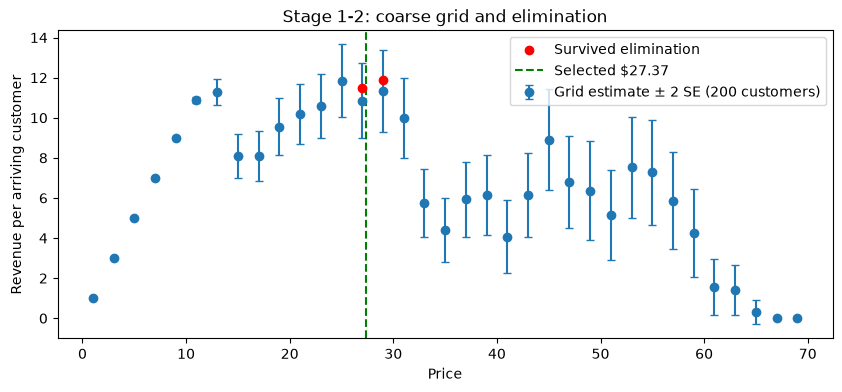

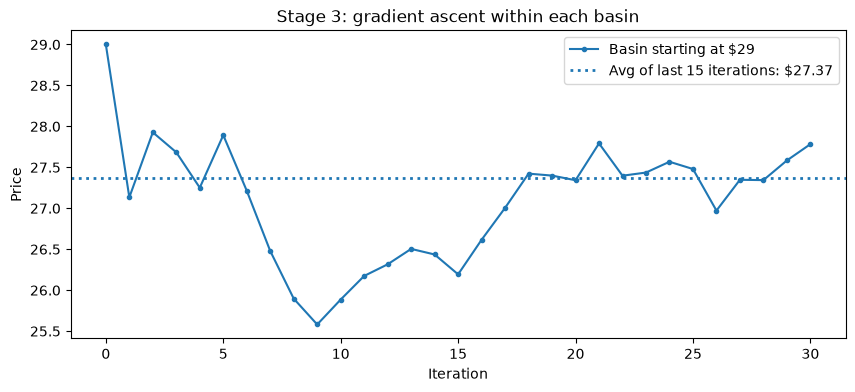

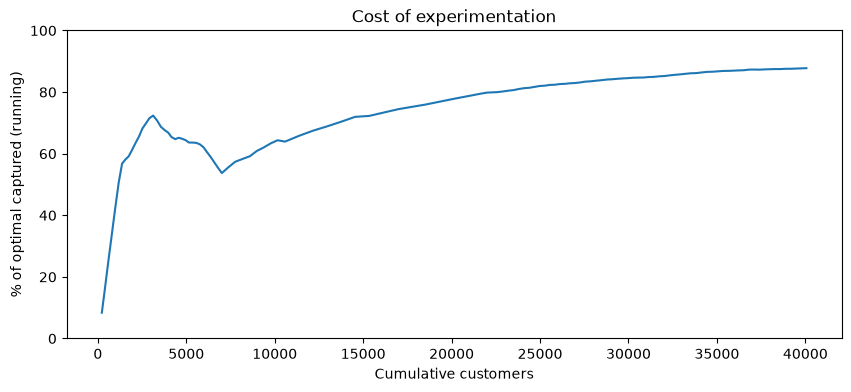

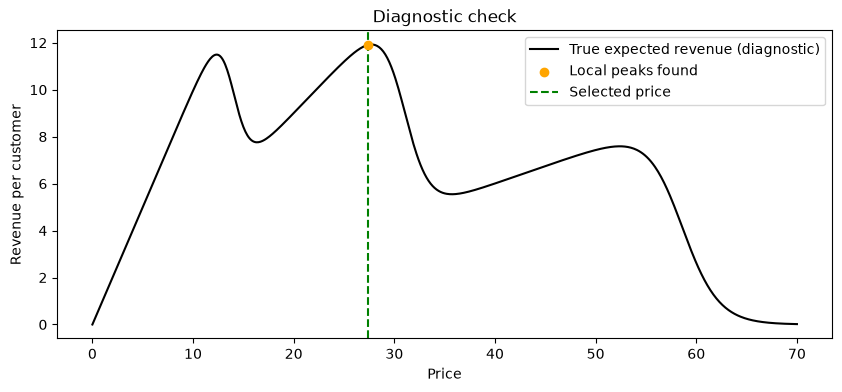

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(grid_table["price"], grid_table["mean_revpc"], yerr=2 * grid_table["se"],
            fmt="o", capsize=3, label="Grid estimate ± 2 SE (200 customers)")
ax.scatter(survivors["price"], survivors["mean_revpc"], color="red", zorder=3, label="Survived elimination")
ax.axvline(best_price, color="green", linestyle="--", label=f"Selected ${best_price:.2f}")
ax.set(xlabel="Price", ylabel="Revenue per arriving customer", title="Stage 1-2: coarse grid and elimination")
ax.legend()

fig, ax = plt.subplots(figsize=(10, 4))
for i, (start, path) in enumerate(ascent_paths.items()):         # changed
    color = f"C{i}"                                              # new
    ax.plot(np.r_[0, path["iteration"]], np.r_[start, path["next_price"]], marker=".", color=color,   # changed
            label=f"Basin starting at ${start:g}")
    half = len(path) // 2                                        # new
    avg_last = path["next_price"].iloc[half:].mean()             # new
    ax.axhline(avg_last, color=color, linestyle=":", linewidth=2,        # new
               label=f"Avg of last {len(path) - half} iterations: ${avg_last:.2f}")
ax.set(xlabel="Iteration", ylabel="Price", title="Stage 3: gradient ascent within each basin")
ax.legend()


fig, ax = plt.subplots(figsize=(10, 4))
cum_c = L["customers"].cumsum()
ax.plot(cum_c, L["revenue"].cumsum() / cum_c / trueoptimal * 100)
ax.set(xlabel="Cumulative customers", ylabel="% of optimal captured (running)", ylim=(0, 100),
       title="Cost of experimentation")

# Diagnostic ONLY: uses the true model, which the search never touches.
fig, ax = plt.subplots(figsize=(10, 4))
pg = np.linspace(0, 70, 701)
ax.plot(pg, pg * purchase_probability(pg), color="black", label="True expected revenue (diagnostic)")
ax.scatter(candidates, [c * purchase_probability(c) for c in candidates], color="orange", zorder=3,
           label="Local peaks found")
ax.axvline(best_price, color="green", linestyle="--", label="Selected price")
ax.set(xlabel="Price", ylabel="Revenue per customer", title="Diagnostic check")
ax.legend()
